# Phase 3E.02 — Performance & Risk Analysis

## 1. Research Objective

This notebook evaluates the gross performance and risk characteristics of the 12-month TSMOM strategy.

The analysis covers cumulative returns, benchmark comparisons, annualized performance metrics, Sharpe Ratio, and drawdowns.

Results are evaluated separately across Train (2010–2017) and Validation (2018–2021).

The Test period (2022–2025) remains untouched until Phase 3F.

In [2]:
from pathlib import Path
import sys

project_root = Path.cwd()

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

if not (project_root / "src").is_dir():
    project_root = project_root.parent

if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import importlib
import src.data
import src.metrics
import src.research
import src.signals
import src.strategy

from src.data import prepare_monthly_prices
from src.strategy import build_tsmom_positions, calculate_portfolio_weights, calculate_portfolio_exposure, calculate_gross_portfolio_returns

In [3]:
asset_universe = {
    "Equities" : ["SPY", "VGK", "EWJ", "EEM"],
    "Commodities" : ["USO", "DBA", "DBB", "DBC"],
    "Bonds" : ["IEF", "TLT", "LQD", "HYG"],
    "Forex" : ["FXE", "FXY", "FXB", "FXA"]
}

tickers = []

for assets in asset_universe.values():
    tickers.extend(assets)

start_date = "2008-01-01"
end_date = "2022-01-01"
lookback = 12

monthly_prices = prepare_monthly_prices(tickers, start_date, end_date)

print(monthly_prices.head())
print(monthly_prices.shape)

signals, positions = build_tsmom_positions(monthly_prices, lookback=lookback)

print(positions.head())
print(positions.isna().sum().sum())
print(positions.dropna().head())
print(positions.shape)

portfolio_weights = calculate_portfolio_weights(positions)
gross_exposure, net_exposure = calculate_portfolio_exposure(portfolio_weights)

print(portfolio_weights.head())
print(gross_exposure.dropna().head())
print(net_exposure.dropna().head())

Ticker            DBA        DBB        DBC        EEM        EWJ        FXA  \
Date                                                                           
2008-01-31  31.200176  19.611866  27.033497  30.937836  36.718548  65.858322   
2008-02-29  35.054855  21.755016  30.046463  31.554827  36.170078  68.784790   
2008-03-31  30.744690  20.388248  29.771803  30.370552  35.708218  67.721039   
2008-04-30  30.871212  20.388248  31.569595  33.145882  38.335091  70.257103   
2008-05-31  29.816872  19.385418  33.750256  34.194565  39.085644  71.677902   

Ticker             FXB         FXE         FXY        HYG        IEF  \
Date                                                                   
2008-01-31  173.245605  136.197525   93.910004  30.854898  56.444160   
2008-02-29  173.586060  139.362091   96.129997  30.278105  57.143616   
2008-03-31  174.066681  145.244690  100.239998  30.564566  57.907829   
2008-04-30  175.017471  144.052872   95.949997  31.602816  56.507942   
2008-05

## 2. Data Preparation & Gross Portfolio Returns

This section reconstructs monthly gross portfolio returns using the validated functions from previous research phases.

The analysis uses the 16-ETF universe and the predefined 12-month TSMOM strategy, with lagged Equal Notional portfolio weights.

Performance will be evaluated separately on Train (2010–2017) and Validation (2018–2021), before transaction costs and slippage.

In [4]:
importlib.reload(src.strategy)

asset_returns, weighted_returns, gross_portfolio_returns = calculate_gross_portfolio_returns(monthly_prices, portfolio_weights)

print(asset_returns.head())
print(weighted_returns.head())
print(gross_portfolio_returns.tail())

print(gross_portfolio_returns.shape)
print(gross_portfolio_returns.isna().sum().sum())

Ticker           DBA       DBB       DBC       EEM       EWJ       FXA  \
Date                                                                     
2008-01-31       NaN       NaN       NaN       NaN       NaN       NaN   
2008-02-29  0.123547  0.109278  0.111453  0.019943 -0.014937  0.044436   
2008-03-31 -0.122955 -0.062825 -0.009141 -0.037531 -0.012769 -0.015465   
2008-04-30  0.004115  0.000000  0.060386  0.091382  0.073565  0.037449   
2008-05-31 -0.034153 -0.049187  0.069075  0.031638  0.019579  0.020223   

Ticker           FXB       FXE       FXY       HYG       IEF       LQD  \
Date                                                                     
2008-01-31       NaN       NaN       NaN       NaN       NaN       NaN   
2008-02-29  0.001965  0.023235  0.023640 -0.018694  0.012392 -0.007063   
2008-03-31  0.002769  0.042211  0.042755  0.009461  0.013374 -0.005972   
2008-04-30  0.005462 -0.008206 -0.042797  0.033969 -0.024174  0.012446   
2008-05-31  0.000468 -0.000179 -0.013

## 3. Train & Validation Split

This section separates gross portfolio returns into the predefined Train (2010–2017) and Validation (2018–2021) periods.

The two samples will be evaluated independently to assess performance consistency without accessing the Test dataset.

In [5]:
train_returns = gross_portfolio_returns.loc["2010-01":"2017-12"]
validation_returns = gross_portfolio_returns.loc["2018-01":"2021-12"]

print(train_returns.shape)
print(train_returns.isna().sum().sum())

print(validation_returns.shape)
print(validation_returns.isna().sum().sum())

(96,)
0
(48,)
0


## 4. Cumulative Portfolio Returns

This section calculates cumulative gross portfolio performance separately for Train and Validation.

Monthly returns are compounded to measure portfolio growth over time, using an initial portfolio value of 1.0.

Date
2017-08-31    1.029544
2017-09-30    1.028257
2017-10-31    1.034076
2017-11-30    1.040633
2017-12-31    1.060664
Freq: ME, dtype: float64
Date
2021-08-31    0.991046
2021-09-30    0.995834
2021-10-31    1.018105
2021-11-30    0.985084
2021-12-31    1.012934
Freq: ME, dtype: float64


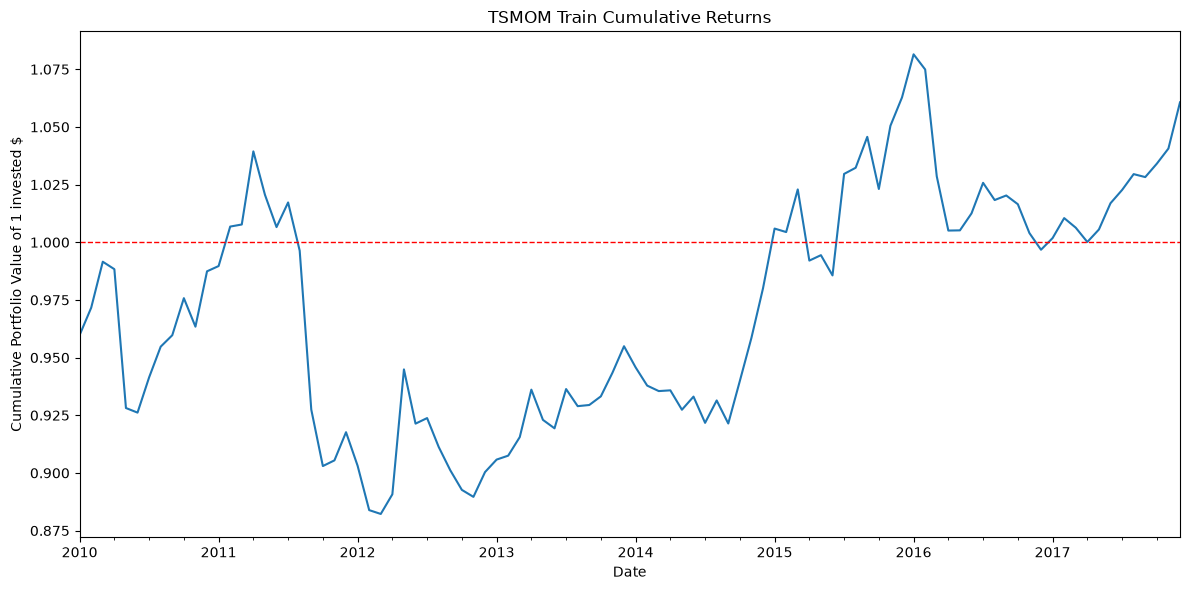

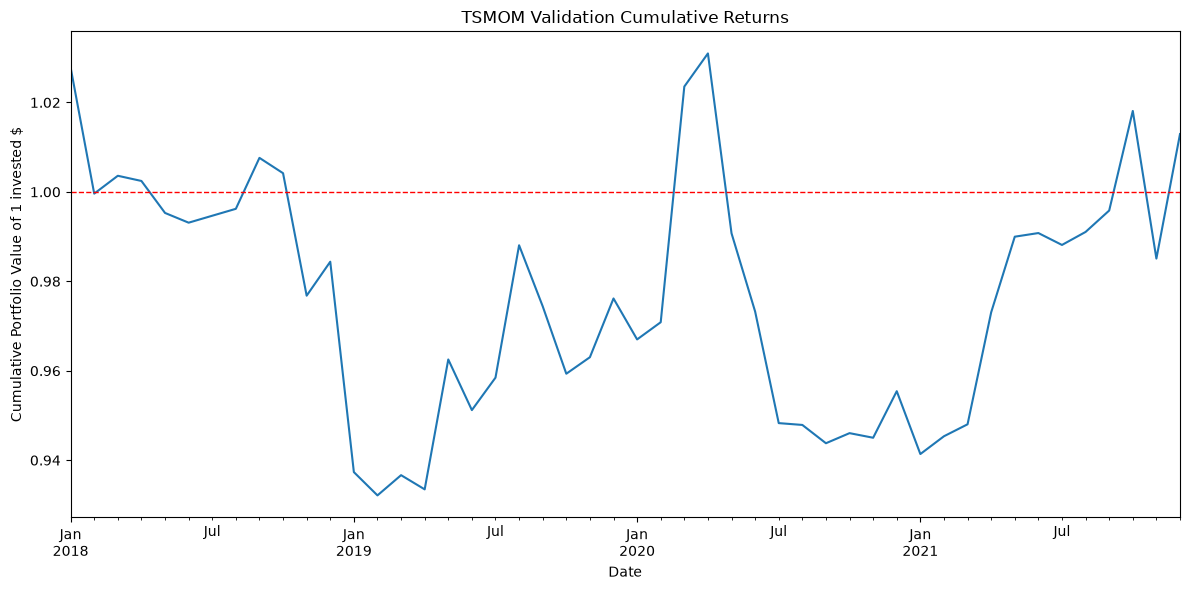

In [6]:
cumulative_train_returns = (1 + train_returns).cumprod()

cumulative_validation_returns = (1 + validation_returns).cumprod()

print(cumulative_train_returns.tail())
print(cumulative_validation_returns.tail())

ctr = cumulative_train_returns.plot(figsize=(12,6))
ctr.set_title("TSMOM Train Cumulative Returns")
ctr.set_xlabel("Date")
ctr.set_ylabel("Cumulative Portfolio Value of 1 invested $")
ctr.axhline(1, color="red", linestyle="--", linewidth=1)

plt.tight_layout()
plt.show()

cvr = cumulative_validation_returns.plot(figsize=(12, 6))
cvr.set_title("TSMOM Validation Cumulative Returns")
cvr.set_xlabel("Date")
cvr.set_ylabel("Cumulative Portfolio Value of 1 invested $")
cvr.axhline(1, color="red", linestyle="--", linewidth=1)

plt.tight_layout()
plt.show()

## 5. Benchmark Construction

This section constructs an equal-weighted, long-only benchmark across the same 16 ETFs.

Benchmark returns will be calculated separately for Train and Validation to provide a consistent reference for evaluating TSMOM performance.

In [ ]:
benchmark_weights = pd.DataFrame(
    1 / len(portfolio_weights.columns),
    index=portfolio_weights.index,
    columns=portfolio_weights.columns
)

print((benchmark_weights.sum(axis=1, min_count=16) == 1).sum())
print(benchmark_weights.shape)

benchmark_weighted_returns = (benchmark_weights * asset_returns)
benchmark_returns = benchmark_weighted_returns.sum(axis=1, min_count=16)
print(benchmark_weighted_returns.shape)
print(benchmark_weighted_returns.head())
print(benchmark_weighted_returns.isna().sum())

print(benchmark_returns.shape)
print(benchmark_returns.head())
print(benchmark_returns.isna().sum())


benchmark_train_returns  = benchmark_returns.loc["2010-01":"2017-12"]
benchmark_validation_returns = benchmark_returns.loc["2018-01":"2021-12"]

print(benchmark_train_returns.shape)
print(benchmark_train_returns.isna().sum())

print(benchmark_validation_returns.shape)
print(benchmark_validation_returns.isna().sum())

cumulative_benchmark_train = (1 + benchmark_train_returns).cumprod()
cumulative_benchmark_validation = (1 + benchmark_validation_returns).cumprod()

print(cumulative_benchmark_train.iloc[-1])
print(cumulative_benchmark_validation.iloc[-1])

168
(168, 16)
(168, 16)
Ticker           DBA       DBB       DBC       EEM       EWJ       FXA  \
Date                                                                     
2008-01-31       NaN       NaN       NaN       NaN       NaN       NaN   
2008-02-29  0.007722  0.006830  0.006966  0.001246 -0.000934  0.002777   
2008-03-31 -0.007685 -0.003927 -0.000571 -0.002346 -0.000798 -0.000967   
2008-04-30  0.000257  0.000000  0.003774  0.005711  0.004598  0.002341   
2008-05-31 -0.002135 -0.003074  0.004317  0.001977  0.001224  0.001264   

Ticker           FXB       FXE       FXY       HYG       IEF       LQD  \
Date                                                                     
2008-01-31       NaN       NaN       NaN       NaN       NaN       NaN   
2008-02-29  0.000123  0.001452  0.001477 -0.001168  0.000774 -0.000441   
2008-03-31  0.000173  0.002638  0.002672  0.000591  0.000836 -0.000373   
2008-04-30  0.000341 -0.000513 -0.002675  0.002123 -0.001511  0.000778   
2008-05-31  0

## 6. Benchmark Performance Comparison

This section compares cumulative gross performance between the TSMOM strategy and the Equal-Weighted Long-Only benchmark.

Train and Validation are analyzed separately using normalized wealth indices.

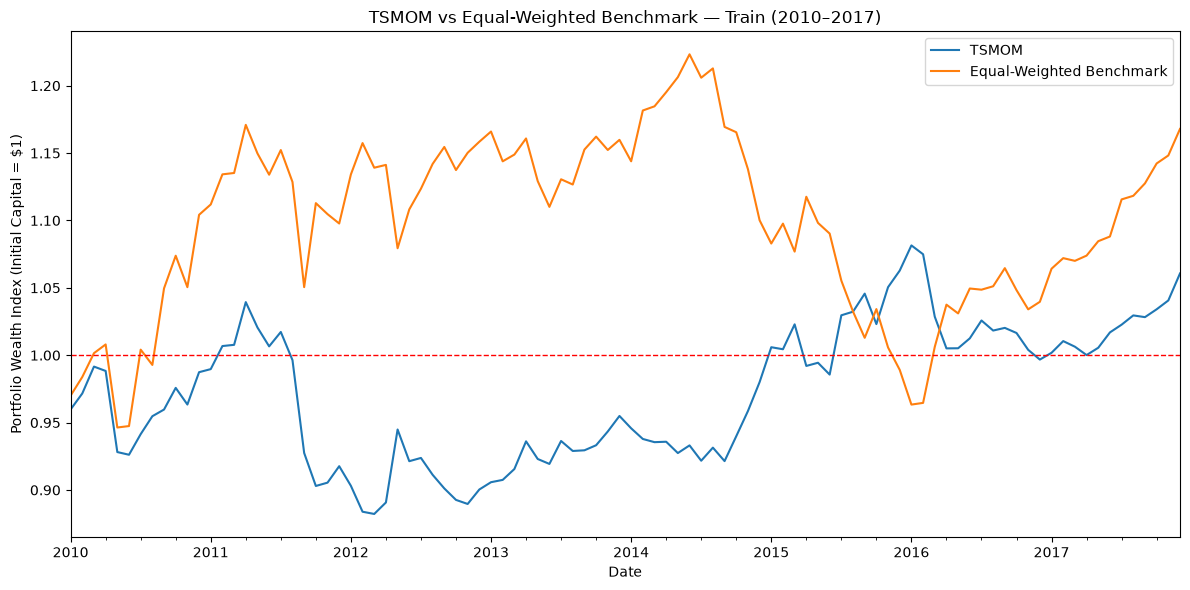

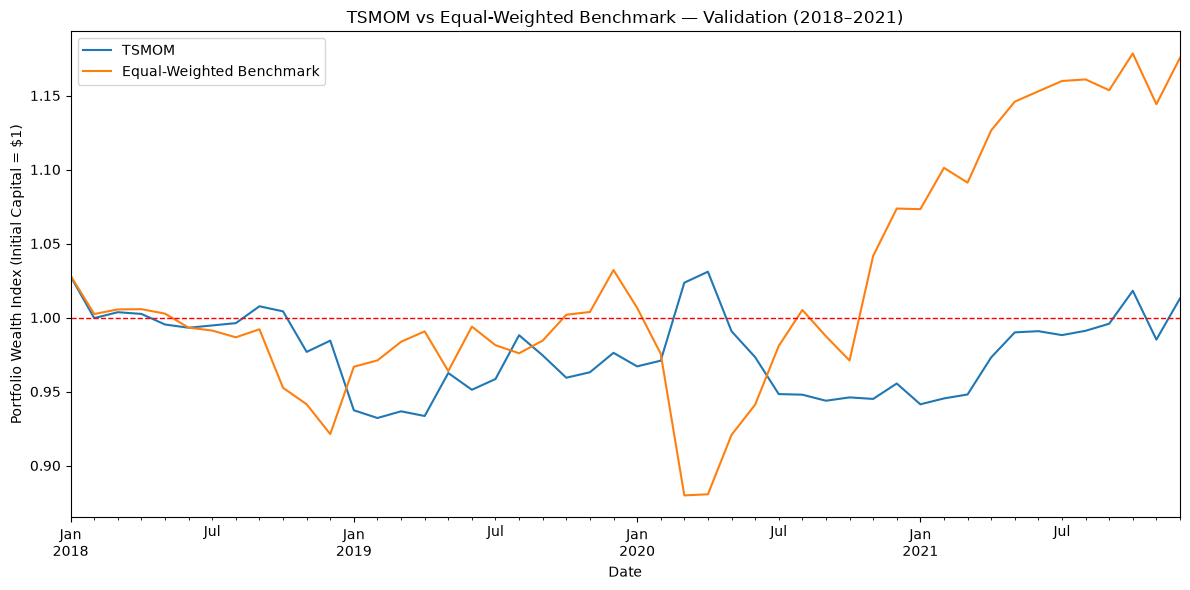

In [8]:
ax_ = cumulative_train_returns.plot(figsize=(12, 6), label="TSMOM")
cumulative_benchmark_train.plot(ax=ax_, label="Equal-Weighted Benchmark")

ax_.set_title("TSMOM vs Equal-Weighted Benchmark — Train (2010–2017)")
ax_.set_xlabel("Date")
ax_.set_ylabel("Portfolio Wealth Index (Initial Capital = $1)")
ax_.axhline(1, color="red", linestyle="--", linewidth=1)
ax_.legend()

plt.tight_layout()
plt.show()

ay_ = cumulative_validation_returns.plot(figsize=(12, 6), label="TSMOM")
cumulative_benchmark_validation.plot(ax=ay_, label="Equal-Weighted Benchmark")

ay_.set_title("TSMOM vs Equal-Weighted Benchmark — Validation (2018–2021)")
ay_.set_xlabel("Date")
ay_.set_ylabel("Portfolio Wealth Index (Initial Capital = $1)")
ay_.axhline(1, color="red", linestyle="--", linewidth=1)
ay_.legend()

plt.tight_layout()
plt.show()

## 7. Performance & Risk Metrics

This section evaluates annualized returns, volatility, Sharpe Ratio, and maximum drawdown for TSMOM and the benchmark.

Metrics are calculated separately for Train and Validation to assess risk-adjusted performance.

In [9]:
train_cagr = (cumulative_train_returns.iloc[-1] / 1) ** (12/len(train_returns)) - 1
validation_cagr = (cumulative_validation_returns.iloc[-1] / 1) ** (12 / len(validation_returns)) - 1

print(f"Train CAGR : {train_cagr:.2%}")
print(f"Validation CAGR : {validation_cagr:.2%}")

benchmark_train_cagr = (cumulative_benchmark_train.iloc[-1] / 1) ** (12 / len(train_returns)) - 1
benchmark_validation_cagr = (cumulative_benchmark_validation.iloc[-1] / 1) ** (12 / len(validation_returns)) - 1

print(f"Train Benchmark CAGR : {benchmark_train_cagr:.2%}")
print(f"Validation Benchmark CAGR : {benchmark_validation_cagr:.2%}")

print("\n")

train_volatility = train_returns.std() * np.sqrt(12)
validation_volatility = validation_returns.std() * np.sqrt(12)

benchmark_train_volatility = benchmark_train_returns.std() * np.sqrt(12)
benchmark_validation_volatility = benchmark_validation_returns.std() * np.sqrt(12)

print(f"Train Volatility : {train_volatility:.2%}")
print(f"Validation Volatility : {validation_volatility:.2%}")

print(f"Train Benchmark Volatility : {benchmark_train_volatility:.2%}")
print(f"Validation Benchmark Volatility : {benchmark_validation_volatility:.2%}")

print("\n")

risk_free_rate = 0

train_sharpe_ratio = (train_returns.mean() * 12 - risk_free_rate) / train_volatility 
validation_sharpe_ratio = (validation_returns.mean() * 12 - risk_free_rate) / validation_volatility

benchmark_train_sharpe_ratio = (benchmark_train_returns.mean() * 12 - risk_free_rate) / benchmark_train_volatility
benchmark_validation_sharpe_ratio = (benchmark_validation_returns.mean() * 12 - risk_free_rate) / benchmark_validation_volatility

print(f"Train Sharpe Ratio : {train_sharpe_ratio:.2f}")
print(f"Validation Sharpe Ratio : {validation_sharpe_ratio:.2f}")

print(f"Benchmark Train Sharpe Ratio : {benchmark_train_sharpe_ratio:.2f}")
print(f"Benchmark Validation Sharpe Ratio : {benchmark_validation_sharpe_ratio:.2f}")


print("\n")

train_running_max = cumulative_train_returns.cummax().clip(lower=1)
validation_running_max = cumulative_validation_returns.cummax().clip(lower=1)

benchmark_train_running_max = cumulative_benchmark_train.cummax().clip(lower=1)
benchmark_validation_running_max = cumulative_benchmark_validation.cummax().clip(lower=1)

train_dd = (cumulative_train_returns / train_running_max) - 1
validation_dd = (cumulative_validation_returns / validation_running_max) - 1

benchmark_train_dd = (cumulative_benchmark_train / benchmark_train_running_max) - 1
benchmark_validation_dd = (cumulative_benchmark_validation / benchmark_validation_running_max) - 1

train_max_dd = train_dd.min()
validation_max_dd = validation_dd.min()

benchmark_train_max_dd = benchmark_train_dd.min()
benchmark_validation_max_dd = benchmark_validation_dd.min()

print(f"Train Max DD : {train_max_dd:.2%}")
print(f"Validation Max DD : {validation_max_dd:.2%}")

print(f"Benchmark Train Max DD : {benchmark_train_max_dd:.2%}")
print(f"Benchmark Validation Max DD : {benchmark_validation_max_dd:.2%}")

Train CAGR : 0.74%
Validation CAGR : 0.32%
Train Benchmark CAGR : 1.96%
Validation Benchmark CAGR : 4.13%


Train Volatility : 6.57%
Validation Volatility : 6.59%
Train Benchmark Volatility : 8.16%
Validation Benchmark Volatility : 9.60%


Train Sharpe Ratio : 0.14
Validation Sharpe Ratio : 0.08
Benchmark Train Sharpe Ratio : 0.28
Benchmark Validation Sharpe Ratio : 0.47


Train Max DD : -15.12%
Validation Max DD : -9.31%
Benchmark Train Max DD : -21.25%
Benchmark Validation Max DD : -14.75%


## 8. Drawdown Analysis & Visualization

This section visualizes historical portfolio drawdowns to compare downside risk between TSMOM and the Equal-Weighted Benchmark across Train and Validation.

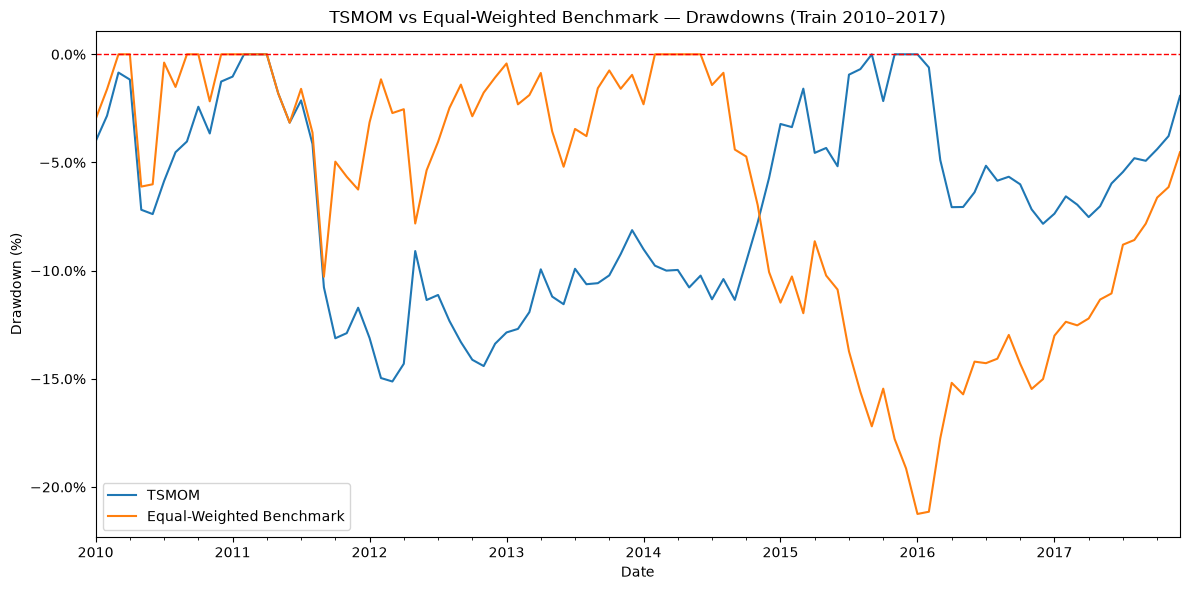

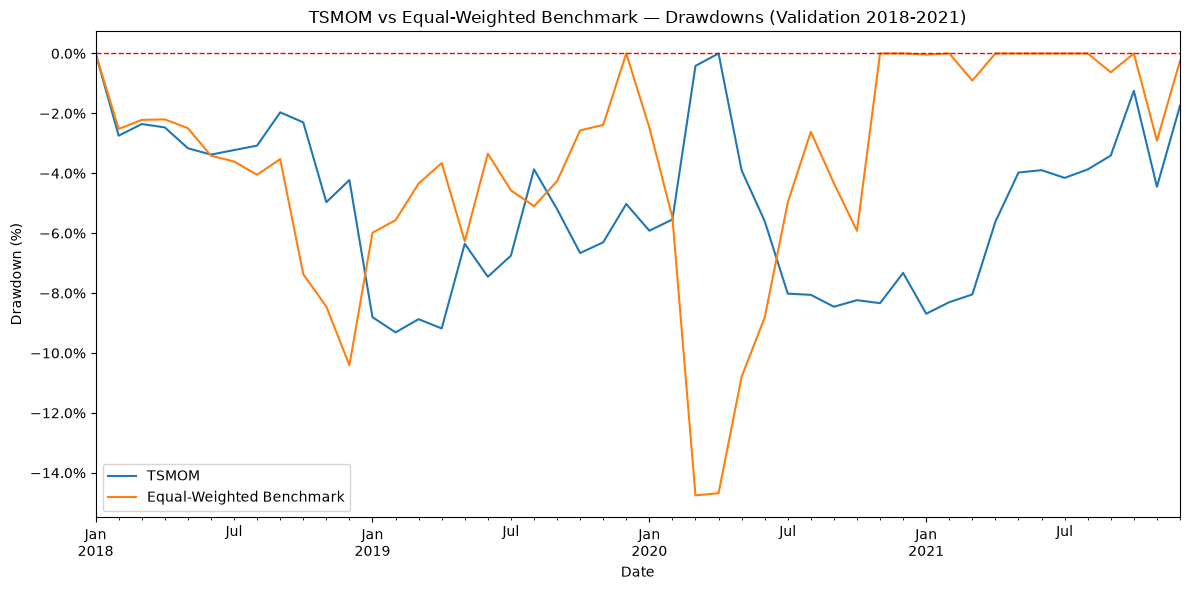

In [10]:
from matplotlib.ticker import PercentFormatter

ax = train_dd.plot(figsize=(12,6), label="TSMOM")
benchmark_train_dd.plot(ax=ax, label="Equal-Weighted Benchmark")

ax.set_title("TSMOM vs Equal-Weighted Benchmark — Drawdowns (Train 2010–2017)")
ax.set_xlabel("Date")
ax.set_ylabel("Drawdown (%)")

ax.axhline(0, color="red", linestyle="--", linewidth=1)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))

ax.legend()
plt.tight_layout()
plt.show()

ay = validation_dd.plot(figsize=(12,6), label="TSMOM")
benchmark_validation_dd.plot(ax=ay, label="Equal-Weighted Benchmark")

ay.set_title("TSMOM vs Equal-Weighted Benchmark — Drawdowns (Validation 2018-2021)")
ay.set_xlabel("Date")
ay.set_ylabel("Drawdown (%)")

ay.axhline(0, color="red", linestyle="--", linewidth=1)
ay.yaxis.set_major_formatter(PercentFormatter(1.0))

ay.legend()
plt.tight_layout()
plt.show()

## 9. Performance Summary

This section consolidates CAGR, annualized volatility, Sharpe Ratio, and Maximum Drawdown into a comparative table for TSMOM and the benchmark across Train and Validation.

In [11]:
performance_summary = {"TSMOM Train" : 
                       {
                           "CAGR" : train_cagr,
                           "Annualized Volatility" : train_volatility,
                           "Sharpe Ratio" : train_sharpe_ratio, 
                           "Max Drawdown" : train_max_dd
                       },
                       "Benchmark Train" : 
                       {
                           "CAGR" : benchmark_train_cagr,
                           "Annualized Volatility" : benchmark_train_volatility,
                           "Sharpe Ratio" : benchmark_train_sharpe_ratio,
                           "Max Drawdown" : benchmark_train_max_dd
                       },
                       "TSMOM Validation" :
                       {
                           "CAGR" : validation_cagr,
                           "Annualized Volatility" : validation_volatility, 
                           "Sharpe Ratio" : validation_sharpe_ratio,
                           "Max Drawdown" : validation_max_dd
                       },
                       "Benchmark Validation" : 
                       {
                           "CAGR" : benchmark_validation_cagr,
                           "Annualized Volatility" : benchmark_validation_volatility,
                           "Sharpe Ratio" : benchmark_validation_sharpe_ratio,
                           "Max Drawdown" : benchmark_validation_max_dd
                       }
                       }

# display(performance_summary)

performance_summary_df = pd.DataFrame(performance_summary).T
display(performance_summary_df.style.format({
    "CAGR" : "{:.2%}",
    "Annualized Volatility" : "{:.2%}",
    "Sharpe Ratio" : "{:.3f}",
    "Max Drawdown" : "{:.2%}"
}))

,CAGR,Annualized Volatility,Sharpe Ratio,Max Drawdown
TSMOM Train,0.74%,6.57%,0.145,-15.12%
Benchmark Train,1.96%,8.16%,0.278,-21.25%
TSMOM Validation,0.32%,6.59%,0.081,-9.31%
Benchmark Validation,4.13%,9.60%,0.469,-14.75%


## 10. Performance Metrics Visualization

This section visualizes key performance and risk metrics to facilitate comparison between TSMOM and the Equal-Weighted Benchmark across Train and Validation.

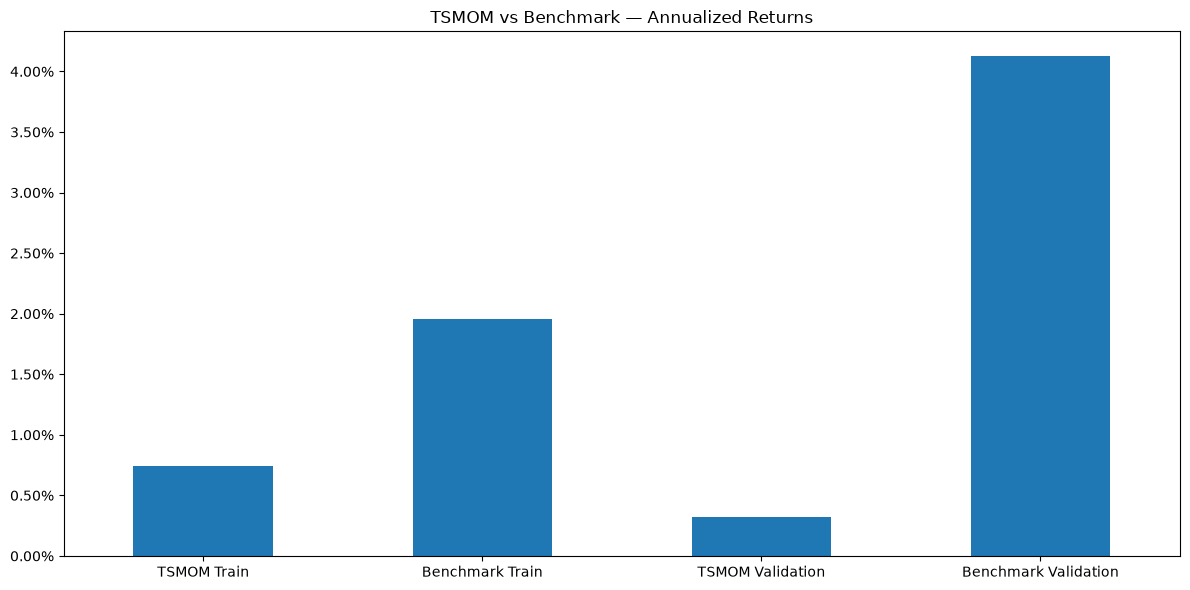

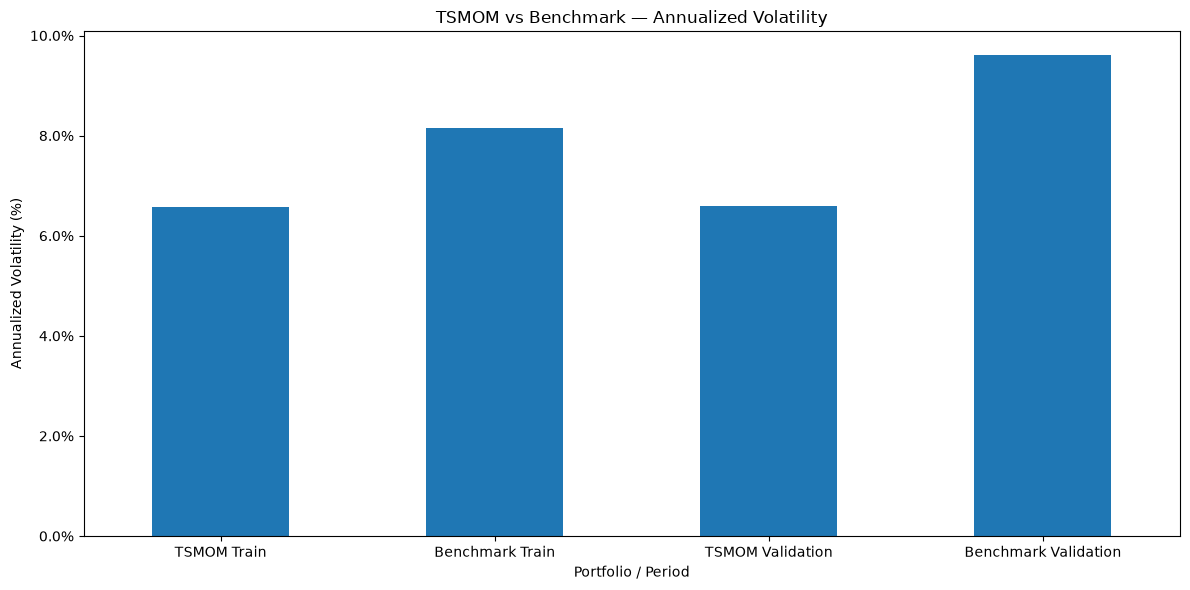

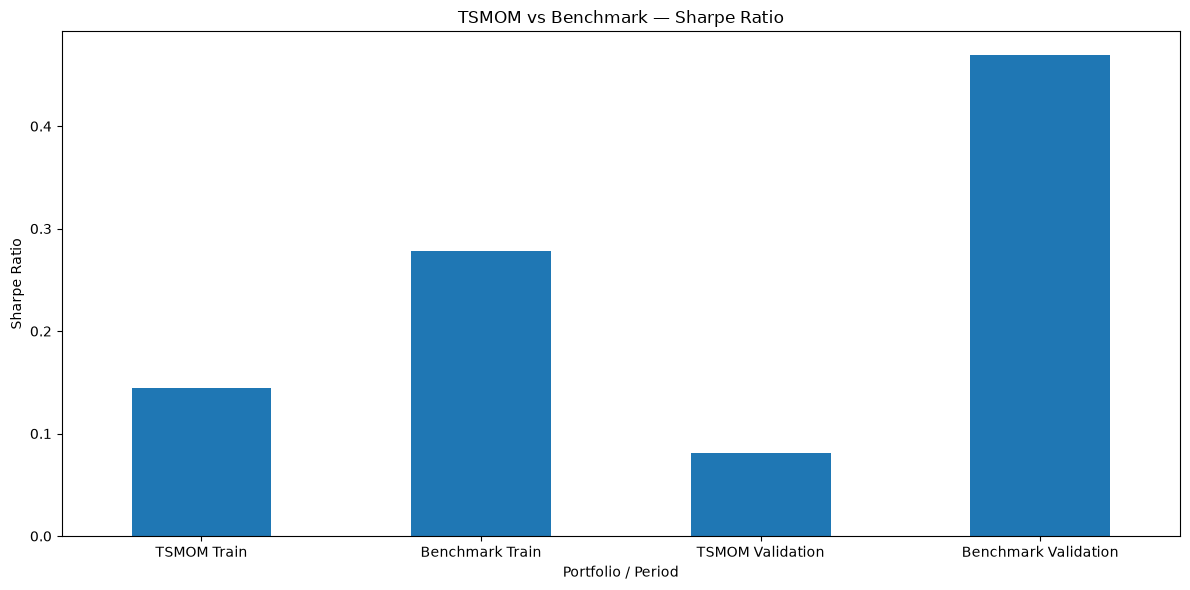

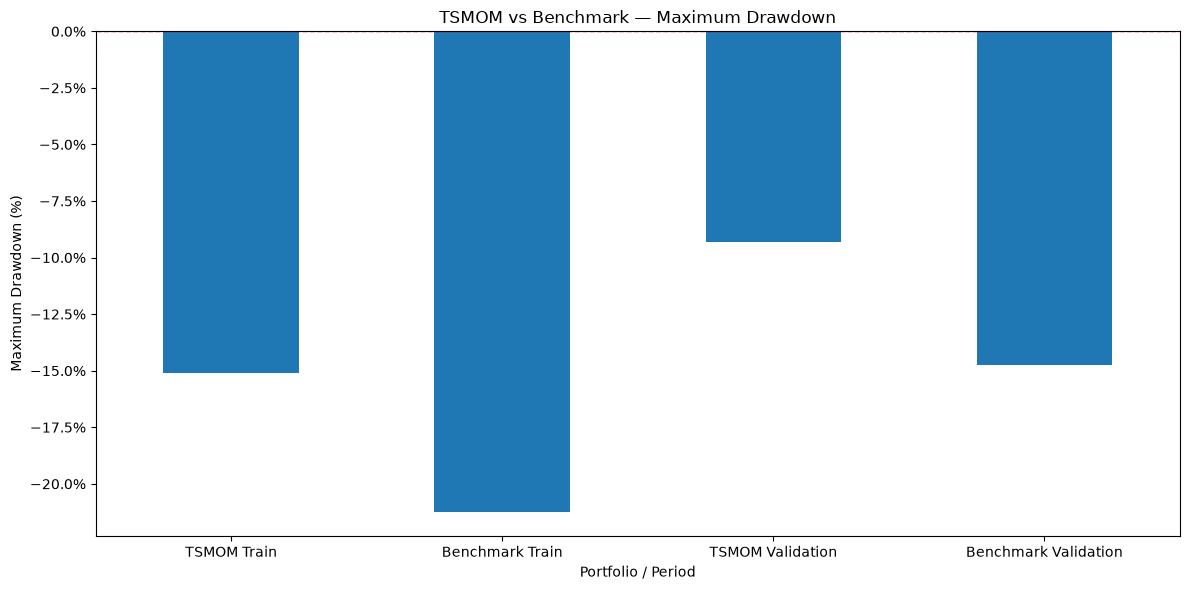

In [12]:
ax = performance_summary_df["CAGR"].plot(kind="bar", figsize=(12, 6), rot=0)
ax.set_title("TSMOM vs Benchmark — Annualized Returns")

ax.yaxis.set_major_formatter(PercentFormatter(1.0))

plt.tight_layout()
plt.show()

ay = performance_summary_df["Annualized Volatility"].plot(kind="bar", figsize=(12,6), rot=0)
ay.set_title("TSMOM vs Benchmark — Annualized Volatility")

ay.set_xlabel("Portfolio / Period")
ay.set_ylabel("Annualized Volatility (%)")

ay.yaxis.set_major_formatter(PercentFormatter(1.0))

plt.tight_layout()
plt.show()

az = performance_summary_df["Sharpe Ratio"].plot(kind="bar", figsize=(12, 6), rot=0)
az.set_title("TSMOM vs Benchmark — Sharpe Ratio")

az.set_xlabel("Portfolio / Period")
az.set_ylabel("Sharpe Ratio")

plt.tight_layout()
plt.show()

ak = performance_summary_df["Max Drawdown"].plot(kind="bar", figsize=(12,6), rot=0)
ak.set_title("TSMOM vs Benchmark — Maximum Drawdown")

ak.set_xlabel("Portfolio / Period")
ak.set_ylabel("Maximum Drawdown (%)")

ak.yaxis.set_major_formatter(PercentFormatter(1.0))
ak.axhline(0, color="red", linestyle="--", linewidth=1)

plt.tight_layout()
plt.show()

## 11. Reusable Performance Metrics

This section consolidates CAGR, annualized volatility, Sharpe Ratio, and maximum drawdown calculations into a reusable function for future backtesting analysis.

In [49]:
from src.metrics import calculate_performance_metrics

metrics = calculate_performance_metrics(train_returns, risk_free_rate=0)

display(metrics)

all_metrics = {"TSMOM Train" : train_returns,
               "Benchmark Train" : benchmark_train_returns,
               "TSMOM Validation" : validation_returns, 
               "Benchmark Validation" : benchmark_validation_returns}

for period, returns in all_metrics.items():
    all_metrics[period] = calculate_performance_metrics(returns, risk_free_rate=0)

all_metrics_df = pd.DataFrame(all_metrics).T
display(all_metrics_df.style.format({
    "CAGR" : "{:.2%}",
    "Annualized Volatility" : "{:.2%}",
    "Sharpe Ratio" : "{:.3f}",
    "Max Drawdown" : "{:.2%}"
}))

print(performance_summary_df.equals(all_metrics_df))

{'CAGR': np.float64(0.0073890893292374304),
 'Annualized Volatility': np.float64(0.06569708296637895),
 'Sharpe Ratio': np.float64(0.14486083390760313),
 'Max Drawdown': np.float64(-0.1512284452232141)}

,CAGR,Annualized Volatility,Sharpe Ratio,Max Drawdown
TSMOM Train,0.74%,6.57%,0.145,-15.12%
Benchmark Train,1.96%,8.16%,0.278,-21.25%
TSMOM Validation,0.32%,6.59%,0.081,-9.31%
Benchmark Validation,4.13%,9.60%,0.469,-14.75%


True


## 12. Conclusion

Phase 3E.02 successfully implemented and validated the performance and risk analysis of the TSMOM strategy against an Equal-Weighted Long-Only benchmark.

### Key Findings

- TSMOM underperformed the benchmark in both Train and Validation periods in terms of CAGR and Sharpe Ratio.
- TSMOM exhibited lower annualized volatility and smaller maximum drawdowns.
- Performance deteriorated slightly between Train and Validation, with no evidence of superior risk-adjusted returns.
- All four performance metrics were consolidated into the reusable `calculate_performance_metrics()` function.
- Numerical consistency between the original calculations and the reusable function was verified using `DataFrame.equals()`.

### Research Limitations

Results are based on gross returns and exclude transaction costs, slippage, and short-financing costs. Historical performance does not establish statistical significance or future profitability.

The Test period (2022–2025) remains untouched to preserve out-of-sample evaluation.

**Status: Phase 3E.02 completed and validated.**

**Next: Phase 3E.03 — Transaction Costs, Turnover & Net Performance.**